<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [TypeSafe System One](https://github.com/Query-farm/vgi-typesafe)

Classify rows, answer yes/no questions and score text from SQL with calibrated confidence

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-typesafe/blob/main/notebooks/02_choose_the_follow_up_per_row.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-typesafe/blob/main/notebooks/README.md)


## 02 · Choose the follow-up per row

**How do we keep different answer types straight while changing what each ticket asks?**
First collect a proposed team, a refund probability and a position on a severity scale.
Then use each proposed team to choose a follow-up question carried by that row.

Every input and answer is synthetic. The bundled local service uses keyword overlap,
not a production model. Its probabilities, confidence, token counts and model labels are
test values: this example establishes SQL contracts and accounting, not accuracy,
calibration, cost or a production routing policy. No ticket is updated.

### Change one team's question

`BILLING_TOPIC="refund"` asks billing tickets about refunds. The experiment uses `"overdue"`.
Shipping still asks about delay and returns still asks about damage. All input text,
first-stage questions and their answers stay fixed; only billing's follow-up changes.
Restart and Run All after changing the value.

In [1]:
BILLING_TOPIC = "refund"

### Start the shared environment

Run the install cell once, then Run All. The [notes](README.md) describe the locked local
runner, hash-verified fixture and how to configure a separate real-service session.
This notebook starts only an ephemeral loopback mock; its answers do not validate calibration.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.20":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.20"
from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.20":
    raise RuntimeError("Install shared example tools v0.3.20, then restart and run all.")

In [3]:
if BILLING_TOPIC not in {"refund", "overdue"}:
    raise ValueError("BILLING_TOPIC must be refund or overdue.")
import hashlib
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vgi_notebooks import connect, finish, prose, theme

from vgi_notebooks.bootstrap import prepare

prepare("typesafe")
from fixtures.typesafe_mock import running  # noqa: E402

for name, digest in json.loads(Path("fixtures/manifest.json").read_text())["sha256"].items():
    assert hashlib.sha256((Path("fixtures") / name).read_bytes()).hexdigest() == digest
mock_context = running(api_key="notebook-mock-only")
mock = mock_context.__enter__()
mock_url = mock.base_url
assert mock_url.startswith("http://127.0.0.1:")
source = "Repository's synthetic keyword mock · TypeSafe v0.3.0 · Local requests only"
theme()
session = connect(globals())
con = session.connection

measures = followups = checks = pd.DataFrame()

### Bind only the disposable local service

The shared connection starts with empty temporary SQL-secret storage and persistent secrets
disabled. This explicit temporary secret supplies both the fake key and loopback URL.
The published worker runs unchanged; no production service or account is contacted.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'typesafe' (TYPE vgi, LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-typesafe@v0.3.0 vgi-typesafe');
CREATE TEMPORARY SECRET notebook_mock (TYPE typesafe, api_key 'notebook-mock-only', base_url '{{ mock_url }}');

,Success


### Preserve the five input records

Three messages have a clear keyword route, one ties shipping and billing, and one is missing.
The IDs are row identities. Keep the missing row and the uncertain route visible rather
than turning either into an automatic decision.

In [5]:
%%sql
CREATE TABLE tickets AS SELECT * FROM (VALUES
 (1,'package delivery lost delay critical outage'),
 (2,'invoice charge refund'),
 (3,'return refund damaged routine question'),
 (4,'package invoice'),
 (5,NULL)
) AS t(ticket_id,body);
SELECT ticket_id,coalesce(body,'[missing input]') AS input FROM tickets ORDER BY ticket_id;

,ticket_id,input
0,1,package delivery lost delay critical outage
1,2,invoice charge refund
2,3,return refund damaged routine question
3,4,package invoice
4,5,[missing input]


### Project three distinct kinds of answer

Each materialized call asks one fixed question over the input column. `choice` supplies
an option plus its distribution and confidence; `noul` supplies a yes/no probability;
`score` supplies a probability-weighted position on the **ordered** levels 0, 1 and 2.
The numbers have different meanings. A middle score can be uncertainty spread across
levels rather than a confident selection of level 1.

These three calls deliberately make separate local requests. If all three questions are
needed together, notebook 01's `ask` combines them into one request per distinct state.
The ledger below measures this run's fixture requests, not production cost.

In [6]:
%%sql
CREATE TABLE routed AS SELECT t.*,c.choice AS team,c.confidence AS route_confidence,
 c.probabilities AS route_probabilities
FROM tickets t,LATERAL typesafe.main.choice(t.body,
 instructions=>'Which team?',criteria=>MAP{
 'shipping':'package delivery lost delay',
 'billing':'invoice charge payment',
 'returns':'return refund damaged'}) c;
CREATE TABLE refund_answers AS SELECT t.ticket_id,n.noul AS refund_probability
FROM tickets t,LATERAL typesafe.main.noul(t.body,
 instructions=>'Does this mention refund?') n;
CREATE TABLE severity_answers AS SELECT t.ticket_id,s.score AS severity_position,
 s.confidence AS severity_confidence,s.probabilities AS severity_probabilities
FROM tickets t,LATERAL typesafe.main.score(t.body,
 instructions=>'How severe is this?',
 criteria=>['routine question','disruptive delay','critical outage']) s;
CREATE TABLE measured AS SELECT r.*,n.refund_probability,s.severity_position,
 s.severity_confidence,s.severity_probabilities,
 list_sum(list_transform(map_keys(s.severity_probabilities),
  lambda level: level*s.severity_probabilities[level])) AS reconstructed_position
FROM routed r JOIN refund_answers n USING(ticket_id)
JOIN severity_answers s USING(ticket_id);
SELECT ticket_id,team,round(route_confidence,3) AS route_confidence,
 round(refund_probability,3) AS refund_probability,
 round(severity_position,3) AS severity_position,
 round(severity_confidence,3) AS severity_confidence
FROM measured ORDER BY ticket_id;

,ticket_id,team,route_confidence,refund_probability,severity_position,severity_confidence
0,1,shipping,0.995,0.269,1.851,0.599
1,2,billing,0.599,0.731,1.000,0.000
2,3,returns,0.969,0.731,0.053,0.839
3,4,shipping,0.194,0.269,1.000,0.000
4,5,None,NaN,NaN,NaN,NaN


In [7]:
flat_request_count = len(mock.requests)
assert flat_request_count == 12
assert all(len(r["questions"]) == 1 for r in mock.requests)
prose(
    f"**{flat_request_count} local requests** cover three one-question calls over four non-NULL bodies. The fifth input remains present with NULL answers; it makes no request. Separate calls are not promised to share a cache."
)

**12 local requests** cover three one-question calls over four non-NULL bodies. The fifth input remains present with NULL answers; it makes no request. Separate calls are not promised to share a cache.

In [8]:
%%sql measures <<
SELECT ticket_id,team,route_confidence,refund_probability,severity_position,
 severity_confidence FROM measured ORDER BY ticket_id;

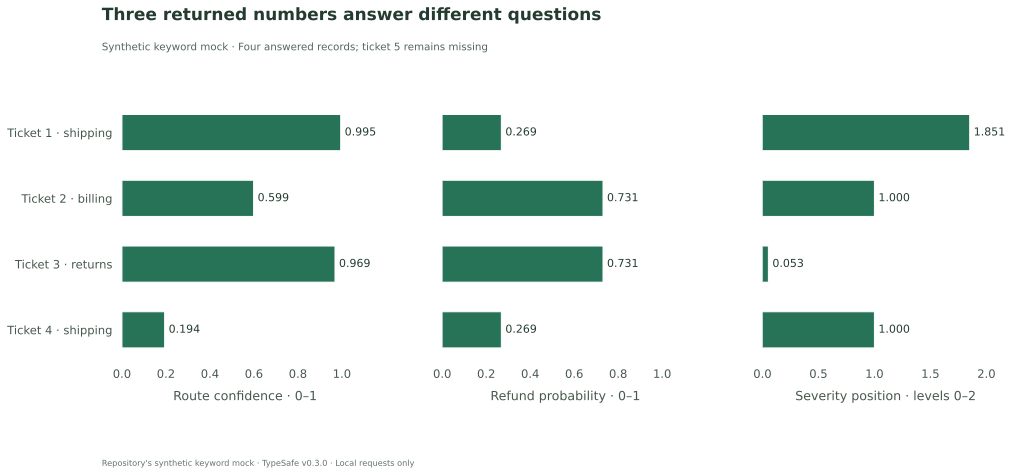

**Ticket 4's proposed shipping route has confidence 0.194.** The mock breaks the shipping/billing tie by option order. A displayed team is not a decision to route. Severity positions use a separate 0–2 scale; their confidence remains visible in the table.

In [9]:
rows = measures[measures.team.notna()]
labels = [f"Ticket {r.ticket_id} · {r.team}" for r in rows.itertuples()]
fig, axes = plt.subplots(1, 3, figsize=(14, 7), sharey=True)
for ax, column, limit, label in zip(
    axes,
    ["route_confidence", "refund_probability", "severity_position"],
    [1.12, 1.12, 2.2],
    ["Route confidence · 0–1", "Refund probability · 0–1", "Severity position · levels 0–2"],
    strict=True,
):
    bars = ax.barh(labels, rows[column], color="#267358", height=0.55)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set(xlim=(0, limit), xlabel=label)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
finish(
    fig,
    "Three returned numbers answer different questions",
    "Synthetic keyword mock · Four answered records; ticket 5 remains missing",
    source,
    name=f"typed-measures-{BILLING_TOPIC}",
)
tie = rows[rows.ticket_id == 4].iloc[0]
prose(
    f"**Ticket 4's proposed {tie.team} route has confidence {tie.route_confidence:.3f}.** The mock breaks the shipping/billing tie by option order. A displayed team is not a decision to route. Severity positions use a separate 0–2 scale; their confidence remains visible in the table."
)

### Use a scalar without changing the yes/no question

`is_true` returns the same kind of probability as `noul`; its name does not mean it
returns a Boolean. Materialize the scalar expression before local filtering. This also
avoids the pinned engine's scalar-in-WHERE beside LATERAL planning limitation.
Compare equivalent questions numerically, retaining NULL rather than replacing it by zero.

In [10]:
%%sql
CREATE TABLE scalar_refund AS SELECT ticket_id,
 typesafe.main.is_true(body,'Does this mention refund?') AS scalar_probability
FROM tickets;
SELECT n.ticket_id,round(n.refund_probability,6) AS table_probability,
 round(s.scalar_probability,6) AS scalar_probability,
 n.refund_probability IS NOT DISTINCT FROM s.scalar_probability AS equivalent,
 s.scalar_probability >= 0.7 AS selected_by_local_policy
FROM refund_answers n JOIN scalar_refund s USING(ticket_id) ORDER BY ticket_id;

,ticket_id,table_probability,scalar_probability,equivalent,selected_by_local_policy
0,1,0.268941,0.268941,True,False
1,2,0.731059,0.731059,True,True
2,3,0.731059,0.731059,True,True
3,4,0.268941,0.268941,True,False
4,5,NaN,NaN,True,<NA>


In [11]:
assert len(mock.requests) - flat_request_count == 4
prose(
    "**All five scalar/table pairs agree, including the NULL pair.** Four additional local requests were made; equivalence does not imply cross-query caching. The local 0.7 filter selects refund-like fixture text only, and is not a recommended production cutoff."
)

**All five scalar/table pairs agree, including the NULL pair.** Four additional local requests were made; equivalence does not imply cross-query caching. The local 0.7 filter selects refund-like fixture text only, and is not a recommended production cutoff.

### Carry the follow-up question with each row

A named question argument is fixed at bind time. `ask_dynamic` instead takes a per-row
questions column, so SQL can construct it from the proposed team. JSON preserves the
question text explicitly and the returned `answers` column is JSON too; extract the known
`follow_up.noul` field rather than pretending the result schema is inferred from row data.

Shipping asks about delay, returns about damage, and billing about the selected topic.
The uncertain shipping/billing tie stays visible with its original route confidence.
This is an inspectable proposed follow-up plan, not an external action.

In [12]:
%%sql
CREATE TABLE question_plan AS SELECT *,
 CASE team WHEN 'shipping' THEN 'delay'
           WHEN 'billing' THEN '{{ BILLING_TOPIC }}'
           WHEN 'returns' THEN 'damaged' END AS topic,
 json_object('follow_up',json_object('type','noul','instructions',
  'Does this mention ' || CASE team WHEN 'shipping' THEN 'delay'
   WHEN 'billing' THEN '{{ BILLING_TOPIC }}' WHEN 'returns' THEN 'damaged'
   ELSE 'missing input' END || '?')) AS questions
FROM routed;
CREATE TABLE follow_up AS SELECT p.*,a.answers,a.model,
 CAST(json_extract(a.answers,'$.follow_up.noul') AS DOUBLE) AS follow_up_probability
FROM question_plan p,LATERAL typesafe.main.ask_dynamic(p.body,p.questions) a;
SELECT ticket_id,team,round(route_confidence,3) AS route_confidence,topic,
 questions,round(follow_up_probability,3) AS follow_up_probability
FROM follow_up ORDER BY ticket_id;

,ticket_id,team,route_confidence,topic,questions,follow_up_probability
0,1,shipping,0.995,delay,"{""follow_up"":{""type"":""noul"",""instructions"":""Do...",0.731
1,2,billing,0.599,refund,"{""follow_up"":{""type"":""noul"",""instructions"":""Do...",0.731
2,3,returns,0.969,damaged,"{""follow_up"":{""type"":""noul"",""instructions"":""Do...",0.731
3,4,shipping,0.194,delay,"{""follow_up"":{""type"":""noul"",""instructions"":""Do...",0.269
4,5,None,NaN,None,"{""follow_up"":{""type"":""noul"",""instructions"":""Do...",NaN


In [13]:
%%sql followups <<
SELECT ticket_id,team,topic,follow_up_probability FROM follow_up ORDER BY ticket_id;

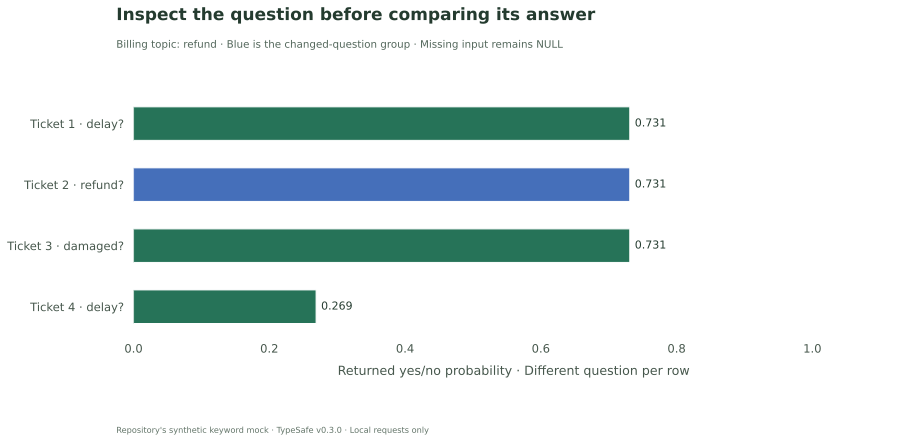

**Billing ticket 2 asks about refund and returns 0.731.** The other routes ask different questions, so their values are not a single priority ranking. The first-stage distributions and route confidences have not changed.

In [14]:
rows = followups[followups.team.notna()]
labels = [f"Ticket {r.ticket_id} · {r.topic}?" for r in rows.itertuples()]
fig, ax = plt.subplots(figsize=(12, 6.5))
colors = ["#456fba" if r.team == "billing" else "#267358" for r in rows.itertuples()]
bars = ax.barh(labels, rows.follow_up_probability, color=colors, height=0.55)
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.invert_yaxis()
ax.set(xlim=(0, 1.12), xlabel="Returned yes/no probability · Different question per row")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Inspect the question before comparing its answer",
    f"Billing topic: {BILLING_TOPIC} · Blue is the changed-question group · Missing input remains NULL",
    source,
    name=f"follow-up-{BILLING_TOPIC}",
)
billing = rows[rows.team == "billing"].iloc[0]
prose(
    f"**Billing ticket {billing.ticket_id} asks about {billing.topic} and returns {billing.follow_up_probability:.3f}.** The other routes ask different questions, so their values are not a single priority ranking. The first-stage distributions and route confidences have not changed."
)

### Reconcile answers and the local request ledger

The fixture should receive 12 shorthand requests, four scalar requests and four dynamic
requests. All are one-question POSTs to loopback. These counts describe this exact query
path, not a production rate limit, invoice or global cache. The final checks also retain
missing inputs, reconstruct the ordered score and reconcile scalar/table equivalence.

In [15]:
%%sql checks <<
SELECT 'All five inputs survive the three joins' AS check_name,count(*)=5 AND count(DISTINCT ticket_id)=5 AS passed FROM measured
UNION ALL SELECT 'Missing input keeps every typed answer NULL',team IS NULL AND refund_probability IS NULL AND severity_position IS NULL FROM measured WHERE ticket_id=5
UNION ALL SELECT 'Choice distributions sum to one',bool_and(abs(list_sum(map_values(route_probabilities))-1)<0.000002) FROM measured WHERE team IS NOT NULL
UNION ALL SELECT 'Route confidence stays in unit interval',bool_and(route_confidence BETWEEN 0 AND 1) FROM measured WHERE team IS NOT NULL
UNION ALL SELECT 'Refund probabilities stay in unit interval',bool_and(refund_probability BETWEEN 0 AND 1) FROM measured WHERE team IS NOT NULL
UNION ALL SELECT 'Score equals weighted ordered positions',bool_and(abs(severity_position-reconstructed_position)<0.000002) FROM measured WHERE team IS NOT NULL
UNION ALL SELECT 'Severity stays on zero-to-two scale',bool_and(severity_position BETWEEN 0 AND 2) FROM measured WHERE team IS NOT NULL
UNION ALL SELECT 'Scalar and table answers including NULL agree',bool_and(n.refund_probability IS NOT DISTINCT FROM s.scalar_probability) FROM refund_answers n JOIN scalar_refund s USING(ticket_id)
UNION ALL SELECT 'Dynamic questions retain five rows',count(*)=5 AND count(DISTINCT ticket_id)=5 FROM follow_up
UNION ALL SELECT 'Dynamic missing input stays unanswered',answers IS NULL AND follow_up_probability IS NULL AND model IS NULL FROM follow_up WHERE ticket_id=5
UNION ALL SELECT 'Dynamic probabilities stay in unit interval',bool_and(follow_up_probability BETWEEN 0 AND 1) FROM follow_up WHERE body IS NOT NULL
UNION ALL SELECT 'Billing alone receives selected topic',bool_and(topic=CASE team WHEN 'billing' THEN '{{ BILLING_TOPIC }}' WHEN 'shipping' THEN 'delay' WHEN 'returns' THEN 'damaged' END) FROM follow_up WHERE team IS NOT NULL;

In [16]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all()
assert len(mock.requests) == 20
assert all(len(r["questions"]) == 1 for r in mock.requests)
dynamic_requests = mock.requests[16:]
assert len(dynamic_requests) == 4
expected = con.execute("SELECT body,questions FROM question_plan WHERE body IS NOT NULL").fetchall()


def key(state, questions):
    return state, json.dumps(questions, sort_keys=True)


assert sorted(key(r["state"], r["questions"]) for r in dynamic_requests) == sorted(
    key(state, json.loads(q)) for state, q in expected
)
prose(
    "**12 SQL checks and the exact dynamic-request audit passed.** The fixture recorded 20 one-question requests. Every POST was handled by the disposable local service; plotting and these checks issued none."
)

,check_name,passed
0,All five inputs survive the three joins,True
1,Missing input keeps every typed answer NULL,True
2,Choice distributions sum to one,True
3,Route confidence stays in unit interval,True
4,Refund probabilities stay in unit interval,True
5,Score equals weighted ordered positions,True
6,Severity stays on zero-to-two scale,True
7,Scalar and table answers including NULL agree,True
8,Dynamic questions retain five rows,True
9,Dynamic missing input stays unanswered,True


**12 SQL checks and the exact dynamic-request audit passed.** The fixture recorded 20 one-question requests. Every POST was handled by the disposable local service; plotting and these checks issued none.

### Experiment · change billing's follow-up

Set `BILLING_TOPIC="overdue"`, restart and Run All. The billing text mentions a refund
but no overdue status. Predict its changed mock probability. Shipping and returns keep
their question text and answers; the five input rows, typed first-stage measurements,
scalar comparison and 20-request accounting remain fixed. The first chart should be identical.

Changing a question changes what an answer means. This fixture demonstrates that boundary;
it does not validate either wording against real users or a production model. Reset `"refund"`
for the saved default.

In [17]:
assert con.execute(
    "SELECT count(*), bool_and(NOT persistent) FROM duckdb_secrets()"
).fetchall() == [(1, True)]
session.close()
mock_context.__exit__(None, None, None)
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-typesafe](https://github.com/Query-farm/vgi-typesafe)